<a href="https://colab.research.google.com/github/arif18-tech/TinyML/blob/main/Lec_06_TinyML_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
try:
  %tensorflow_vesion 2.x
except Exception:
  pass

In [3]:
import tensorflow as tf
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
import tensorflow_hub as hub
import tensorflow_datasets as tfds
import pathlib

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


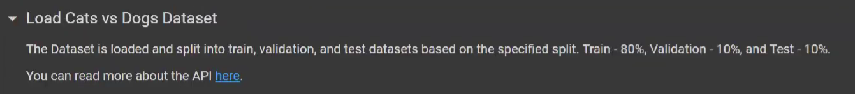

In [4]:
!pip install -q importlib_resources

import tensorflow_datasets as tfds
setattr(tfds.image_classification.cats_vs_dogs, '_URL', "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip")

# load in our dataset
(raw_train, raw_validation, raw_test), metadata = tfds.load('cats_vs_dogs', split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'], with_info=True, as_supervised=True)

# display how much data we have
run_examples = metadata.splits['train'].num_examples
num_classes = metadata.features['label'].num_classes
print()
print("number of data samples:", run_examples)
print("Number of classes:", num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.OKFNIL_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.

number of data samples: 23262
Number of classes: 2


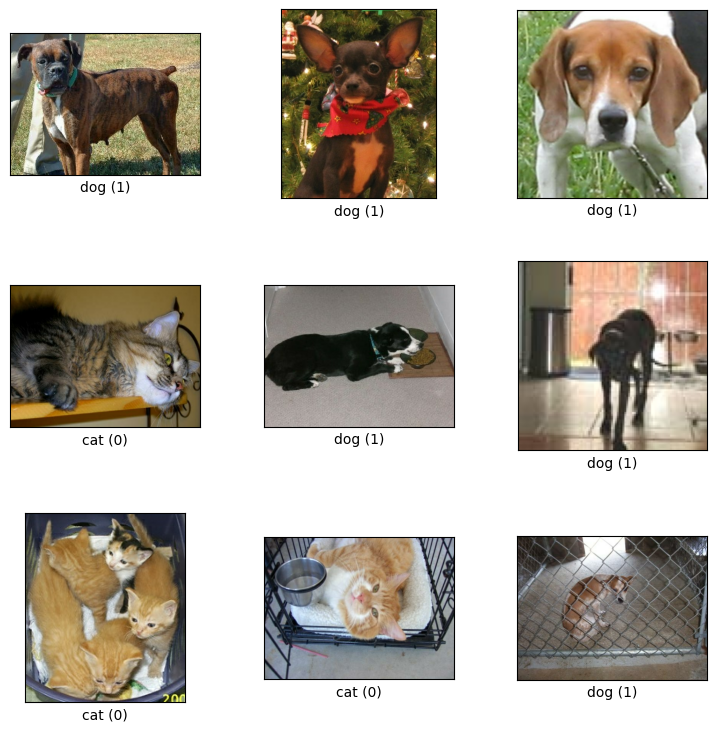

In [ ]:
vis=tfds.visualization.show_examples(raw_train, metadata)

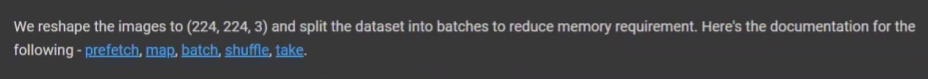

In [19]:
# format images to have normalized pixels
def format_image(image, label):
    image = tf.image.resize(image, (224, 224)) / 255.0
    return image, label
#split the data in training, validation, and test datasets
BATCH_SIZE = 32
train_batches = raw_train.shuffle(run_examples // 4).map(format_image).batch(BATCH_SIZE).prefetch(1)
validation_batches = raw_validation.map(format_image).batch(BATCH_SIZE).prefetch(1)
test_batches = raw_test.map(format_image).batch(1)
# display the shape of our data
for image_batch, label_batch in train_batches.take(1):
    pass
print("Shape of one batch of images:", image_batch.shape)
print("label example:", label_batch[10].numpy())

Shape of one batch of images: (32, 224, 224, 3)
label example: 0


In [20]:
print(len(train_batches))
print(len(validation_batches))
print(len(test_batches))

582
73
2326


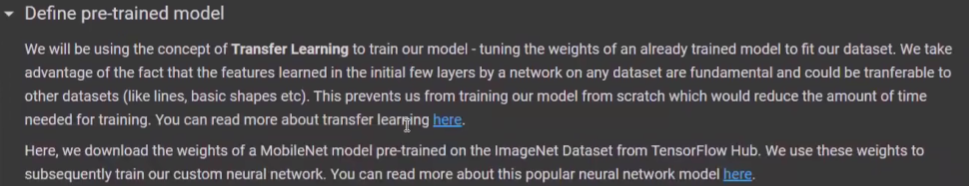

In [8]:
module_selection = ("mobilenet_v2", 224, 1280) #(pre-trained model, input pixel size, output feature vector size)
handle_base, pixels, FV_SIZE = module_selection
print(pixels)
MODULE_HANDLE ="https://tfhub.dev/google/tf2-preview/{}/feature_vector/4".format(handle_base)
IMAGE_SIZE = (pixels, pixels)
print("Using {} with input size {} and output dimension {}".format(
    MODULE_HANDLE, IMAGE_SIZE, FV_SIZE
))

224
Using https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4 with input size (224, 224) and output dimension 1280


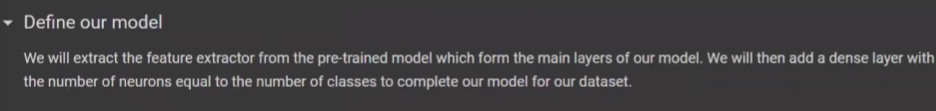

In [9]:

import tensorflow as tf
import tensorflow_hub as hub
import tf_keras

# Instantiate the Hub layer
hub_layer = hub.KerasLayer(
    MODULE_HANDLE,
    input_shape=IMAGE_SIZE + (3,),
    output_shape=[FV_SIZE],
    trainable=False
)

print("Building model with", MODULE_HANDLE)

# Build model
model = tf_keras.Sequential([
    hub_layer,
    tf_keras.layers.Dense(num_classes, activation='softmax')
])

# Display model summary
model.summary()


Building model with https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1280)              2257984   
                                                                 
 dense (Dense)               (None, 2)                 2562      
                                                                 
Total params: 2260546 (8.62 MB)
Trainable params: 2562 (10.01 KB)
Non-trainable params: 2257984 (8.61 MB)
_________________________________________________________________


In [10]:
LOSS= 'sparse_categorical_crossentropy'
OPTIMIZER= 'adam'
METRICS= ['accuracy']

model.compile(
    optimizer=OPTIMIZER,
    loss=LOSS,
    metrics=METRICS
)

In [34]:
EPOCHS = 5

hist = model.fit(train_batches, epochs= EPOCHS, validation_data=validation_batches)

Epoch 1/5
582/582 [==============================] - 851s 1s/step - loss: 0.0560 - accuracy: 0.9816 - val_loss: 0.0390 - val_accuracy: 0.9871
Epoch 2/5
582/582 [==============================] - 778s 1s/step - loss: 0.0300 - accuracy: 0.9891 - val_loss: 0.0370 - val_accuracy: 0.9884
Epoch 3/5
582/582 [==============================] - 799s 1s/step - loss: 0.0250 - accuracy: 0.9917 - val_loss: 0.0392 - val_accuracy: 0.9888
Epoch 4/5
582/582 [==============================] - 778s 1s/step - loss: 0.0209 - accuracy: 0.9927 - val_loss: 0.0400 - val_accuracy: 0.9893
Epoch 5/5
582/582 [==============================] - 704s 1s/step - loss: 0.0195 - accuracy: 0.9936 - val_loss: 0.0380 - val_accuracy: 0.9888


In [11]:
CATS_VS_DOGS_SAVED_MODEL = "saved_model"
tf.saved_model.save(model, CATS_VS_DOGS_SAVED_MODEL)

In [12]:
converter = tf.lite.TFLiteConverter.from_saved_model (CATS_VS_DOGS_SAVED_MODEL)
#<YOUR CODE HERE>
tflite_model = converter.convert()
tflite_models_dir = pathlib.Path("/content/")
tflite_model_file = tflite_models_dir/'modell.tflite'
print("Size of modell:", tflite_model_file.write_bytes(tflite_model))

Size of modell: 8876872


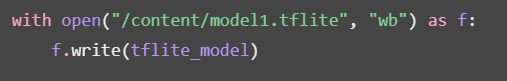

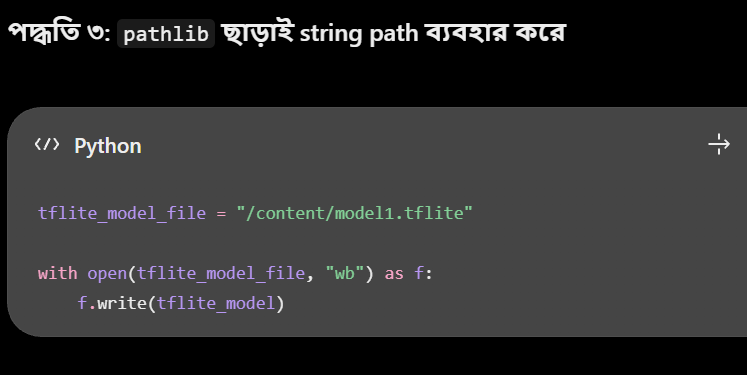

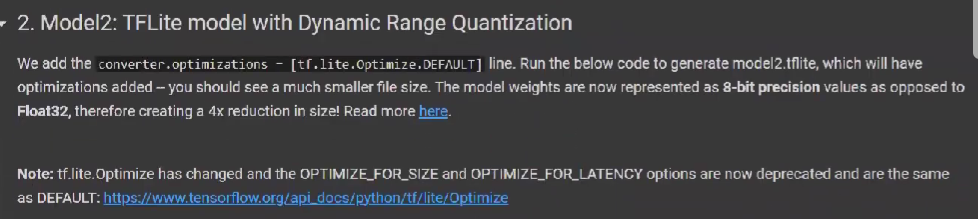

In [13]:
converter = tf.lite.TFLiteConverter.from_saved_model(CATS_VS_DOGS_SAVED_MODEL)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
# optimization
tflite_model = converter.convert()
tflite_models_dir = pathlib.Path("/content/")
tflite_model_file = tflite_models_dir/'model2.tflite'
tflite_model_file.write_bytes(tflite_model)

2511384

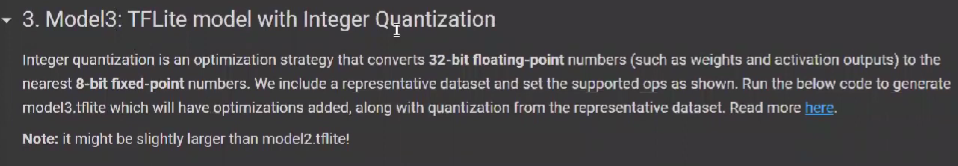

In [21]:
converter = tf.lite.TFLiteConverter.from_saved_model(CATS_VS_DOGS_SAVED_MODEL)
converter.optimizations = [tf.lite.Optimize.DEFAULT] #optimization
def representative_data_gen(): #quantization from representative dataset
  for input_value, _ in test_batches.take(100):
    yield [input_value]


converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
tflite_model = converter.convert()
tflite_models_dir = pathlib.Path("/content/")
tflite_model_file = tflite_models_dir/'model3.tflite'
tflite_model_file.write_bytes(tflite_model)

2714520

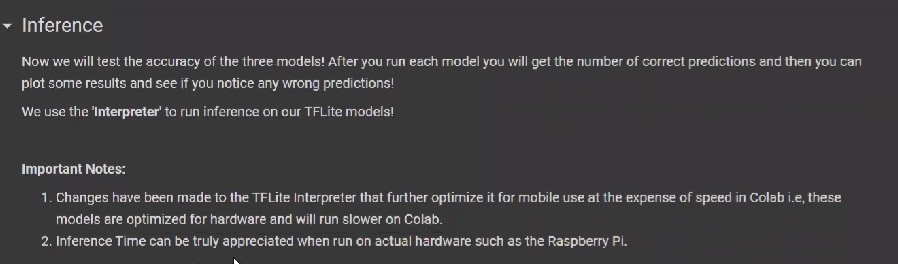

In [22]:
from tqdm import tqdm
#Load TFLite model and allocate Lensors.
tflite_model_file = 'modell.tflite' # Change the filename here for Model 2
interpreter = tf.lite.Interpreter(model_path=tflite_model_file)
interpreter.allocate_tensors()

input_index = interpreter.get_input_details()[0]["index"]
output_index = interpreter.get_output_details()[0]["index"]

predictions = []
test_labels, test_imgs = [], []
for img, label in tqdm(test_batches.take(100)):
  interpreter.set_tensor(input_index, img)
  interpreter.invoke()
  predictions.append(interpreter.get_tensor(output_index))
  test_labels.append(label.numpy()[0])
  test_imgs.append(img)

score = 0
for item in range(0,100):
  prediction = np.argmax(predictions[item])
  label = test_labels[item]
  if prediction==label:
    score=score+1


print()
print("out of 100 predictions I got" + str(score) + "correct")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
100%|██████████| 100/100 [00:01<00:00, 87.23it/s]


out of 100 predictions I got28correct


In [24]:
class_names = ['cat', 'dog']
def plot_image(i, predictions_array, true_label, img):
    predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    img = np.squeeze(img)

    plt.imshow(img, cmap=plt.cm.binary)
    predicted_label = np.argmax(predictions_array)

    if predicted_label == true_label:
        color = 'green'
    else:
        color = 'red'

    plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label], 100*np.max(predictions_array), class_names[true_label]), color=color)

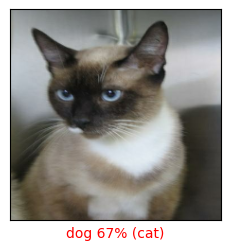

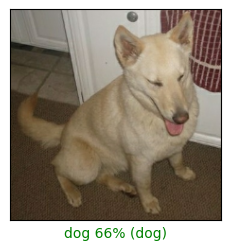

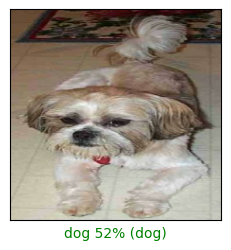

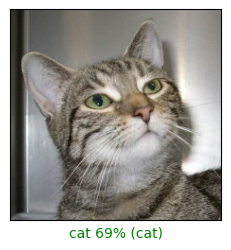

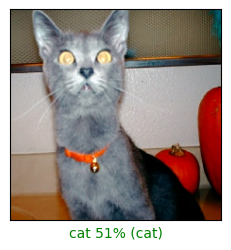

In [27]:
max_index = 5 #@param (type:"slider", min:1, max: 100, step:1)
for index in range(0, max_index):
  plt.figure(figsize=(6,3))
  plt.subplot(1,2,1)
  plot_image(index, predictions, test_labels, test_imgs)
  plt.show()